# Экзаменационная задача №4. Оптимизация рекламной нагрузки для платформы видеоконтента

- **Курс:** Экономика информатизации, лекция №5 «Экономика внимания (Attention Economy)»
- **Студент:** Солдатов Сергей Юрьевич
- **Группа:** ПИ4-1
- **Дата:** 2026-11-24

In [1]:
# ============================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №04: ОПТИМИЗАЦИЯ РЕКЛАМНОЙ НАГРУЗКИ
#                             ДЛЯ ПЛАТФОРМЫ ВИДЕОКОНТЕНТА
# ============================================================================
# Дата: 2026-11-24
# Студент: Солдатов Сергей Юрьевич
# Группа: ПИ4-1
# ============================================================================

# Библиотеки: pandas — таблицы, matplotlib — графики
import json
import os

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter
import pandas as pd

MLN = 1_000_000  # рублей в миллионе


def fmt(value, digits=0):
    """Число в привычной записи: 9 200 или 0,6."""
    value = round(value, digits) + 0          # «+ 0» убирает минус у нуля
    text = f"{value:,.{digits}f}"
    return text.replace(",", " ").replace(".", ",").replace("-", "−")


def pct(value, digits=0):
    """Доля в процентах: 0.05 -> 5%."""
    return fmt(value * 100, digits) + "%"


def signed(value, digits=0):
    """Число со знаком: +20 или −20."""
    return ("+" if value > 0 else "") + fmt(value, digits)


def show(table, digits=0):
    """Показывает таблицу, записав каждое число в привычном виде."""
    view = table.astype(object)
    for column in table.columns:
        for row in table.index:
            view.loc[row, column] = fmt(table.loc[row, column], digits)
    display(view)


# Единый вид графиков: светлый фон, сетка, без верхней и правой рамки
plt.rcParams.update({
    "figure.figsize": (9, 4.8),
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

# Подписи делений на осях графиков — в той же записи чисел, что и в таблицах
AXIS_FORMAT = FuncFormatter(lambda value, position: fmt(value))

# Цвета на графиках
BLUE, ORANGE, GREEN, PURPLE, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#7c5cc4", "#52514e"

# Графики сохраняем в reports/figures (ноутбук запускается из папки notebooks)
FIG_DIR = os.path.join("..", "reports", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

## Экономическая постановка задачи

**Проблема.** Платформа «ВидеоСервис» зарабатывает на рекламе и подписке. Чем больше рекламы показывают
пользователю, тем выше рекламный доход. Но реклама отнимает внимание: пользователи смотрят меньше, а часть из них
уходит и перестает платить за подписку. Нужно найти рекламную нагрузку, при которой общая прибыль максимальна.

**Актуальность.** В экономике внимания (лекция №5) дефицитный ресурс — не информация, а внимание человека.
Платформа продает это внимание рекламодателям. Если продать слишком много, пользователи уйдут, и платформа потеряет
больше, чем заработает. Поэтому рекламная нагрузка — один из главных параметров, которыми управляет платформа.

**Цель.** Найти оптимальную рекламную нагрузку для платформы «ВидеоСервис» и обосновать ее расчетами.

**Задачи:**
1. посчитать рекламный доход, доход от подписки и потери от оттока для каждого уровня нагрузки;
2. посчитать общую прибыль и найти нагрузку, при которой она максимальна;
3. проверить, как ответ зависит от CPM и от оттока;
4. дать рекомендации по нагрузке для сегментов пользователей и составить план мониторинга.

## 1. Исходные данные

### 1.1. Параметры проекта

Все значения взяты из условия задачи (методичка, лекция №5, раздел «Экзаменационная задача»).

In [2]:
# Все исходные данные лежат в одном словаре: меняем значение здесь — пересчитывается всё
BASE = {
    "users": 5_000_000,              # число активных пользователей
    "subscription": 300,             # доход от подписки, руб. с пользователя в месяц
    "cpm": 20,                       # доход от рекламы за 1 000 показов (CPM), руб.
    "videos_per_day": 10,            # среднее число видео в день на пользователя
    # Влияние рекламной нагрузки: (показов в день, отток пользователей, время просмотра в минутах)
    "levels": [
        (0, 0.00, 120),
        (10, 0.00, 115),
        (20, 0.02, 110),
        (30, 0.05, 100),
        (40, 0.10, 90),
        (50, 0.18, 75),
        (60, 0.30, 60),
    ],
    "cac": 2_000,                    # CAC — затраты на привлечение одного пользователя, руб.
    "lifetime": 24,                  # средний срок жизни пользователя, месяцев
    "rate": 0.12,                    # ставка дисконтирования, годовых
    "days": 30,                      # дней в месяце — число 30 из формулы задания 1
    "cpm_variants": (10, 20, 30),    # значения CPM для анализа чувствительности (задание 7), руб.
    "churn_shift": 0.20,             # изменение оттока в анализе чувствительности (задание 8)
}

# Таблица «Влияние рекламной нагрузки» строится из словаря, поэтому всегда совпадает с расчетом
rows = []
for load, churn, minutes in BASE["levels"]:
    rows.append({
        "Рекламная нагрузка, показов в день": load,
        "Отток пользователей": pct(churn),
        "Время просмотра, мин": fmt(minutes),
    })
display(pd.DataFrame(rows).set_index("Рекламная нагрузка, показов в день"))

# Остальные параметры
cpm_text = []
for cpm in BASE["cpm_variants"]:
    cpm_text.append(fmt(cpm))
source_table = pd.DataFrame(
    [
        ("Число активных пользователей", fmt(BASE["users"])),
        ("Доход от подписки, руб. с пользователя в месяц", fmt(BASE["subscription"])),
        ("Доход от рекламы за 1 000 показов (CPM), руб.", fmt(BASE["cpm"])),
        ("Среднее число видео в день на пользователя", fmt(BASE["videos_per_day"])),
        ("CAC, руб. на пользователя", fmt(BASE["cac"])),
        ("Средний срок жизни пользователя, месяцев", fmt(BASE["lifetime"])),
        ("Ставка дисконтирования, годовых", pct(BASE["rate"])),
        ("Дней в месяце (из формулы задания 1)", fmt(BASE["days"])),
        ("CPM в анализе чувствительности, руб.", " / ".join(cpm_text)),
        ("Изменение оттока в анализе чувствительности", "±" + pct(BASE["churn_shift"])),
    ],
    columns=["Параметр", "Значение"],
)
display(source_table)

,Отток пользователей,"Время просмотра, мин"
"Рекламная нагрузка, показов в день",,
0,0%,120
10,0%,115
20,2%,110
30,5%,100
40,10%,90
50,18%,75
60,30%,60


,Параметр,Значение
0,Число активных пользователей,5 000 000
1,"Доход от подписки, руб. с пользователя в месяц",300
2,"Доход от рекламы за 1 000 показов (CPM), руб.",20
3,Среднее число видео в день на пользователя,10
4,"CAC, руб. на пользователя",2 000
5,"Средний срок жизни пользователя, месяцев",24
6,"Ставка дисконтирования, годовых",12%
7,Дней в месяце (из формулы задания 1),30
8,"CPM в анализе чувствительности, руб.",10 / 20 / 30
9,Изменение оттока в анализе чувствительности,±20%


### 1.2. Справочные данные

Справочные данные вводятся там, где они нужны: формулы из условия и лекции №5 — в разделе 2.1, условие оптимума
из лекции — в разделе 2.4, целевые значения метрик из лекции — в разделе 2.6.

### 1.3. Дополнительные условия (допущения)

В условии есть места, которые можно понять по-разному. Каждое такое место разобрано перед тем расчетом, на который
оно влияет: допущения Д1–Д4 — в разделе 2.3, Д5–Д6 — в разделе 2.4, Д7 — в разделе 2.5, Д8–Д9 — в разделе 2.6.

## 2. Расчеты

### 2.1. Математическая модель

Обозначения: $N$ — число пользователей, $Imp$ — рекламная нагрузка (показов в день на пользователя), $d(Imp)$ — доля
оттока при этой нагрузке, $P$ — доход от подписки с пользователя в месяц, $T$ — срок жизни пользователя.

**Рекламный доход за месяц** (формула задания 1):

$$R_{рекл}(Imp) = N \cdot Imp \cdot 30 \cdot \frac{CPM}{1000}$$

**Число ушедших пользователей:** $N_{ушло}(Imp) = N \cdot d(Imp)$.

**Доход от подписки за месяц** (формула задания 2):

$$R_{подп}(Imp) = (N - N_{ушло}) \cdot P$$

**Потери от оттока** (формула задания 3):

$$L(Imp) = N_{ушло} \cdot CAC + N_{ушло} \cdot ARPU \cdot T$$

**Общая прибыль** (задание 4) и **оптимальная нагрузка** (задание 5):

$$\pi(Imp) = R_{рекл}(Imp) + R_{подп}(Imp) - L(Imp), \qquad Imp^* = \arg\max \pi(Imp)$$

**Откуда формулы.** Формулы рекламного дохода, дохода от подписки и потерь от оттока записаны в заданиях 1–3
условия. Рекламный доход — это формула из лекции №5 (раздел 5.2): доход = показы × CPM / 1000. Прибыль как разность
дохода и потерь и задача $\max \pi(Imp)$ — лекция №5, разделы 6.1 и 6.3. В лекции доход $R(Imp)$ — это доход
от рекламы. У «ВидеоСервиса» есть еще подписка, поэтому в прибыль входит и доход от подписки из задания 2.

**Почему эти методы.** По лекции (раздел 6.1) оптимальная рекламная нагрузка — это количество рекламных показов,
максимизирующее общую прибыль платформы с учетом эффекта насыщения внимания пользователей. Насыщение в условии
задано таблицей: с ростом нагрузки падает время просмотра и растет отток. Уровней в таблице семь, поэтому считаем
прибыль для каждого уровня и выбираем наибольшую. Результат проверяем условием оптимума из лекции: нагрузку стоит
повышать, пока прирост дохода больше прироста потерь.

### 2.2. Функции расчета

Шесть коротких функций. Первые четыре — формулы из раздела 2.1, пятая собирает из них таблицу по всем уровням
нагрузки, шестая находит в таблице максимум прибыли.

In [3]:
# ARPU — средний доход с пользователя в месяц; в расчете это доход от подписки (допущение Д3)
ARPU = BASE["subscription"]


def lost_users(churn):
    """Число ушедших пользователей: вся база × доля оттока."""
    return BASE["users"] * churn


def ad_revenue(load, cpm):
    """Рекламный доход за месяц по формуле задания 1, руб."""
    return BASE["users"] * load * BASE["days"] * cpm / 1000


def subscription_revenue(churn):
    """Доход от подписки за месяц по формуле задания 2, руб."""
    return (BASE["users"] - lost_users(churn)) * BASE["subscription"]


def churn_losses(churn):
    """Потери от оттока по формуле задания 3, руб."""
    lost = lost_users(churn)
    return lost * BASE["cac"] + lost * ARPU * BASE["lifetime"]


def profit_table(cpm, churn_factor):
    """Таблица по всем уровням нагрузки. churn_factor — на сколько умножить отток из условия."""
    rows = []
    for load, churn, minutes in BASE["levels"]:
        churn = min(churn * churn_factor, 1)         # отток в этом варианте (не больше 100%)
        ad = ad_revenue(load, cpm)
        subscription = subscription_revenue(churn)
        losses = churn_losses(churn)
        rows.append({
            "Нагрузка": load,
            "Отток": churn,
            "Ушло": lost_users(churn),
            "Рекламный доход": ad,
            "Доход подписки": subscription,
            "Потери оттока": losses,
            "Прибыль": ad + subscription - losses,   # формула задания 4
        })
    return pd.DataFrame(rows).set_index("Нагрузка")


def best_load(table):
    """Нагрузка, при которой прибыль в таблице наибольшая."""
    return table["Прибыль"].idxmax()

### 2.3. Часть 1. Доходы и потери (задания 1–3)

Для этих расчетов нужны четыре допущения.

| № | Допущение | Почему так |
|---|---|---|
| Д1 | «Показов в день» — это показы одному пользователю. Рекламный доход считается от всей базы (5 млн) и получается за месяц | В формуле задания 1 стоит «Пользователи», без вычета оттока, и множитель 30 — число дней в месяце. По лекции (тест 4) рекламная нагрузка — количество рекламных показов на пользователя |
| Д2 | Отток в таблице — доля базы, которая уходит при данной нагрузке. Число ушедших = 5 млн × отток. Подписку платят все активные пользователи; доход от подписки — за месяц, от оставшихся | В формуле задания 2 отток вычитается из числа пользователей, значит, это число людей. На 300 руб. умножается вся оставшаяся база. Подписка задана в рублях в месяц |
| Д3 | ARPU в формуле потерь — доход от подписки, 300 руб. в месяц. Тогда ARPU × 24 — это LTV: доход с пользователя за срок жизни | Это единственный доход «на пользователя в месяц», заданный в условии. Рекламный доход по формуле задания 1 считается от всей базы и при оттоке не уменьшается, поэтому в ARPU его не включаем. В критериях оценки: Потери = Отток × LTV + Отток × CAC |
| Д4 | Ставка дисконтирования (12% годовых) в расчете не применяется | Формула потерь в задании 3 записана без дисконтирования: Отток × ARPU × 24. Берем ее как есть |

In [4]:
# Задание 1. Рекламный доход за месяц для каждого уровня нагрузки
base_table = profit_table(BASE["cpm"], 1)        # базовый расчет: CPM и отток из условия
loads = list(base_table.index)                   # уровни нагрузки из таблицы условия
EXAMPLE = loads[2]                               # уровень, на котором показываем расчет по шагам

rows = []
for load in loads:
    impressions = BASE["users"] * load * BASE["days"]        # всего показов за месяц
    rows.append({
        "Нагрузка, показов в день": load,
        "Показов за месяц, млрд": fmt(impressions / 1e9, 1),
        "Рекламный доход, млн руб. в месяц": fmt(base_table.loc[load, "Рекламный доход"] / MLN),
    })
display(pd.DataFrame(rows).set_index("Нагрузка, показов в день"))

# Пример расчета по формуле задания 1
print(f"Пример для нагрузки {EXAMPLE} показов в день: "
      f"{fmt(BASE['users'])} × {EXAMPLE} × {BASE['days']} × {BASE['cpm']} / 1000 = "
      f"{fmt(ad_revenue(EXAMPLE, BASE['cpm']))} руб.")

,"Показов за месяц, млрд","Рекламный доход, млн руб. в месяц"
"Нагрузка, показов в день",,
0,"0,0",0
10,"1,5",30
20,"3,0",60
30,"4,5",90
40,"6,0",120
50,"7,5",150
60,"9,0",180


Пример для нагрузки 20 показов в день: 5 000 000 × 20 × 30 × 20 / 1000 = 60 000 000 руб.


In [5]:
# Задание 2. Доход от подписки за месяц для каждого уровня нагрузки
rows = []
for load in loads:
    lost = base_table.loc[load, "Ушло"]                      # ушло пользователей
    rows.append({
        "Нагрузка, показов в день": load,
        "Отток": pct(base_table.loc[load, "Отток"]),
        "Ушло пользователей": fmt(lost),
        "Осталось пользователей": fmt(BASE["users"] - lost),
        "Доход от подписки, млн руб. в месяц": fmt(base_table.loc[load, "Доход подписки"] / MLN),
    })
display(pd.DataFrame(rows).set_index("Нагрузка, показов в день"))

# Пример расчета по формуле задания 2
example_lost = base_table.loc[EXAMPLE, "Ушло"]
print(f"Пример для нагрузки {EXAMPLE} показов в день: "
      f"({fmt(BASE['users'])} − {fmt(example_lost)}) × {BASE['subscription']} = "
      f"{fmt(base_table.loc[EXAMPLE, 'Доход подписки'])} руб.")

,Отток,Ушло пользователей,Осталось пользователей,"Доход от подписки, млн руб. в месяц"
"Нагрузка, показов в день",,,,
0,0%,0,5 000 000,1 500
10,0%,0,5 000 000,1 500
20,2%,100 000,4 900 000,1 470
30,5%,250 000,4 750 000,1 425
40,10%,500 000,4 500 000,1 350
50,18%,900 000,4 100 000,1 230
60,30%,1 500 000,3 500 000,1 050


Пример для нагрузки 20 показов в день: (5 000 000 − 100 000) × 300 = 1 470 000 000 руб.


In [6]:
# Задание 3. Потери от оттока для каждого уровня нагрузки
LTV = ARPU * BASE["lifetime"]                    # доход с пользователя за срок жизни, руб.
LOSS_PER_USER = BASE["cac"] + LTV                # потери при уходе одного пользователя, руб.
print(f"LTV = ARPU × срок жизни = {fmt(ARPU)} × {BASE['lifetime']} = {fmt(LTV)} руб.")
print(f"Потери при уходе одного пользователя = CAC + LTV = {fmt(BASE['cac'])} + {fmt(LTV)} = "
      f"{fmt(LOSS_PER_USER)} руб.")

rows = []
for load in loads:
    lost = base_table.loc[load, "Ушло"]
    rows.append({
        "Нагрузка, показов в день": load,
        "Ушло пользователей": fmt(lost),
        "Отток × CAC, млн руб.": fmt(lost * BASE["cac"] / MLN),
        f"Отток × ARPU × {BASE['lifetime']}, млн руб.": fmt(lost * LTV / MLN),
        "Потери от оттока, млн руб.": fmt(base_table.loc[load, "Потери оттока"] / MLN),
    })
display(pd.DataFrame(rows).set_index("Нагрузка, показов в день"))

# Пример расчета по формуле задания 3
print(f"Пример для нагрузки {EXAMPLE} показов в день: "
      f"{fmt(example_lost)} × {fmt(BASE['cac'])} + {fmt(example_lost)} × {fmt(ARPU)} × "
      f"{BASE['lifetime']} = {fmt(base_table.loc[EXAMPLE, 'Потери оттока'])} руб.")

LTV = ARPU × срок жизни = 300 × 24 = 7 200 руб.
Потери при уходе одного пользователя = CAC + LTV = 2 000 + 7 200 = 9 200 руб.


,Ушло пользователей,"Отток × CAC, млн руб.","Отток × ARPU × 24, млн руб.","Потери от оттока, млн руб."
"Нагрузка, показов в день",,,,
0,0,0,0,0
10,0,0,0,0
20,100 000,200,720,920
30,250 000,500,1 800,2 300
40,500 000,1 000,3 600,4 600
50,900 000,1 800,6 480,8 280
60,1 500 000,3 000,10 800,13 800


Пример для нагрузки 20 показов в день: 100 000 × 2 000 + 100 000 × 300 × 24 = 920 000 000 руб.


### 2.4. Часть 2. Прибыль и оптимальная нагрузка (задания 4–5)

Для прибыли и оптимума нужны два допущения.

| № | Допущение | Почему так |
|---|---|---|
| Д5 | Общая прибыль = рекламный доход + доход от подписки − потери от оттока. Доходы берутся за месяц, потери — одной суммой за весь срок жизни ушедших пользователей | Величины складываются так, как они заданы формулами заданий 1–3. За основу взята модель из лекции (раздел 6.1): прибыль = доход − потери. В лекции доход — только рекламный; здесь к нему добавлен доход от подписки. Других затрат в условии нет |
| Д6 | Оптимальную нагрузку выбираем из семи уровней таблицы | Отток задан только для этих уровней. Какой он между ними, в условии не сказано |

График зависимости прибыли от нагрузки (задание 6) построен в разделе 2.7.

In [7]:
# Задание 4. Общая прибыль для каждого уровня нагрузки, млн руб.
profit_view = pd.DataFrame(index=loads)
profit_view.index.name = "Нагрузка, показов в день"
profit_view["Рекламный доход"] = base_table["Рекламный доход"] / MLN
profit_view["Доход от подписки"] = base_table["Доход подписки"] / MLN
profit_view["Доход всего"] = profit_view["Рекламный доход"] + profit_view["Доход от подписки"]
profit_view["Потери от оттока"] = base_table["Потери оттока"] / MLN
profit_view["Прибыль"] = base_table["Прибыль"] / MLN
print("Доходы за месяц, потери от оттока и прибыль, млн руб.")
show(profit_view)

# Пример расчета по формуле задания 4
row = base_table.loc[EXAMPLE]
print(f"Пример для нагрузки {EXAMPLE} показов в день: "
      f"{fmt(row['Рекламный доход'] / MLN)} + {fmt(row['Доход подписки'] / MLN)} − "
      f"{fmt(row['Потери оттока'] / MLN)} = {fmt(row['Прибыль'] / MLN)} млн руб.")

Доходы за месяц, потери от оттока и прибыль, млн руб.


,Рекламный доход,Доход от подписки,Доход всего,Потери от оттока,Прибыль
"Нагрузка, показов в день",,,,,
0,0,1 500,1 500,0,1 500
10,30,1 500,1 530,0,1 530
20,60,1 470,1 530,920,610
30,90,1 425,1 515,2 300,−785
40,120,1 350,1 470,4 600,−3 130
50,150,1 230,1 380,8 280,−6 900
60,180,1 050,1 230,13 800,−12 570


Пример для нагрузки 20 показов в день: 60 + 1 470 − 920 = 610 млн руб.


In [8]:
# Задание 5. Оптимальная нагрузка — уровень с наибольшей прибылью
optimal = best_load(base_table)
best = base_table.loc[optimal]                   # строка таблицы для оптимальной нагрузки
ad_share = best["Рекламный доход"] / (best["Рекламный доход"] + best["Доход подписки"])

print(f"Ответ на задание 5: оптимальная рекламная нагрузка — {optimal} показов в день.")
print(f"  Прибыль — {fmt(best['Прибыль'] / MLN)} млн руб.")
print(f"  Рекламный доход — {fmt(best['Рекламный доход'] / MLN)} млн руб. в месяц, "
      f"это {pct(ad_share, 1)} всего дохода")
print(f"  Доход от подписки — {fmt(best['Доход подписки'] / MLN)} млн руб. в месяц")
print(f"  Отток — {pct(best['Отток'])}, "
      f"потери от оттока — {fmt(best['Потери оттока'] / MLN)} млн руб.")
print(f"  На одно видео приходится {fmt(optimal / BASE['videos_per_day'], 1)} показа рекламы "
      f"(пользователь смотрит {BASE['videos_per_day']} видео в день)")

Ответ на задание 5: оптимальная рекламная нагрузка — 10 показов в день.
  Прибыль — 1 530 млн руб.
  Рекламный доход — 30 млн руб. в месяц, это 2,0% всего дохода
  Доход от подписки — 1 500 млн руб. в месяц
  Отток — 0%, потери от оттока — 0 млн руб.
  На одно видео приходится 1,0 показа рекламы (пользователь смотрит 10 видео в день)


In [9]:
# Проверка по условию оптимума из лекции №5 (раздел 6.3): dR/dImp = dC/dImp.
# R — рекламный доход. C — потери платформы: снижение дохода от подписки и потери от оттока.
# Нагрузку стоит повышать, пока прирост R на шаге больше прироста C.
rows = []
last_good = loads[0]                             # до какой нагрузки шаги выгодны
still_good = True
for position in range(1, len(loads)):
    previous, current = loads[position - 1], loads[position]
    before, after = base_table.loc[previous], base_table.loc[current]
    # Прирост рекламного дохода на этом шаге
    gain = after["Рекламный доход"] - before["Рекламный доход"]
    # Прирост потерь: на сколько упала подписка и на сколько выросли потери от оттока
    cost = ((before["Доход подписки"] - after["Доход подписки"])
            + (after["Потери оттока"] - before["Потери оттока"]))
    if gain > cost and still_good:
        last_good = current                      # шаг выгоден — идем дальше
    else:
        still_good = False                       # первый невыгодный шаг — дальше не идем
    rows.append({
        "Шаг нагрузки": f"{previous} → {current}",
        "Прирост рекламного дохода, млн руб.": fmt(gain / MLN),
        "Прирост потерь, млн руб.": fmt(cost / MLN),
        "Изменение прибыли, млн руб.": signed((gain - cost) / MLN),
        "Шаг выгоден": "да" if gain > cost else "нет",
    })
display(pd.DataFrame(rows).set_index("Шаг нагрузки"))

if last_good == loads[-1]:
    print(f"Все шаги выгодны: повышать нагрузку выгодно до {last_good} показов в день.")
else:
    print(f"Повышать нагрузку выгодно до {last_good} показов в день: "
          "на следующем шаге потери растут быстрее рекламного дохода.")
print("Это совпадает с максимумом прибыли из задания 5." if last_good == optimal
      else "Это не совпадает с максимумом прибыли из задания 5.")

,"Прирост рекламного дохода, млн руб.","Прирост потерь, млн руб.","Изменение прибыли, млн руб.",Шаг выгоден
Шаг нагрузки,,,,
0 → 10,30,0,+30,да
10 → 20,30,950,−920,нет
20 → 30,30,1 425,−1 395,нет
30 → 40,30,2 375,−2 345,нет
40 → 50,30,3 800,−3 770,нет
50 → 60,30,5 700,−5 670,нет


Повышать нагрузку выгодно до 10 показов в день: на следующем шаге потери растут быстрее рекламного дохода.
Это совпадает с максимумом прибыли из задания 5.


### 2.5. Часть 3. Анализ чувствительности (задания 7–8)

Меняем по одному параметру и смотрим, меняется ли оптимальная нагрузка и прибыль.

| № | Допущение | Почему так |
|---|---|---|
| Д7 | Параметры меняются по одному: сначала CPM (10, 20 и 30 руб.), потом отток. Отток ±20% — это относительное изменение: отток при каждой нагрузке умножается на 0,8 и на 1,2 (например, 2% → 1,6% и 2,4%) | Задания 7 и 8 даны отдельно. Изменение на 20 процентных пунктов дало бы отрицательный отток при малых нагрузках |

In [10]:
# Задание 7. Чувствительность к CPM: прибыль при каждом значении CPM, млн руб.
cpm_tables = {}
for cpm in BASE["cpm_variants"]:
    cpm_tables[cpm] = profit_table(cpm, 1)       # отток — как в условии

cpm_profit = pd.DataFrame(index=loads)
cpm_profit.index.name = "Нагрузка, показов в день"
for cpm, table in cpm_tables.items():
    cpm_profit[f"CPM {fmt(cpm)} руб."] = table["Прибыль"] / MLN
print("Прибыль при разных CPM, млн руб.")
show(cpm_profit)

# Оптимальная нагрузка при каждом CPM
cpm_optima = {}
for cpm, table in cpm_tables.items():
    load = best_load(table)
    cpm_optima[cpm] = load
    print(f"CPM {fmt(cpm)} руб.: оптимальная нагрузка — {load} показов в день, "
          f"прибыль — {fmt(table.loc[load, 'Прибыль'] / MLN)} млн руб., "
          f"рекламный доход — {fmt(table.loc[load, 'Рекламный доход'] / MLN)} млн руб.")

if len(set(cpm_optima.values())) == 1:
    common_load = list(cpm_optima.values())[0]   # общая для всех вариантов оптимальная нагрузка
    print(f"Ответ на задание 7: при любом CPM из условия оптимальная нагрузка одна и та же — "
          f"{common_load} показов в день.")
else:
    print("Ответ на задание 7: оптимальная нагрузка зависит от CPM.")

Прибыль при разных CPM, млн руб.


,CPM 10 руб.,CPM 20 руб.,CPM 30 руб.
"Нагрузка, показов в день",,,
0,1 500,1 500,1 500
10,1 515,1 530,1 545
20,580,610,640
30,−830,−785,−740
40,−3 190,−3 130,−3 070
50,−6 975,−6 900,−6 825
60,−12 660,−12 570,−12 480


CPM 10 руб.: оптимальная нагрузка — 10 показов в день, прибыль — 1 515 млн руб., рекламный доход — 15 млн руб.
CPM 20 руб.: оптимальная нагрузка — 10 показов в день, прибыль — 1 530 млн руб., рекламный доход — 30 млн руб.
CPM 30 руб.: оптимальная нагрузка — 10 показов в день, прибыль — 1 545 млн руб., рекламный доход — 45 млн руб.
Ответ на задание 7: при любом CPM из условия оптимальная нагрузка одна и та же — 10 показов в день.


In [11]:
# Задание 8. Чувствительность к оттоку: отток при каждой нагрузке умножаем на 0,8 и на 1,2
shift = BASE["churn_shift"]
churn_cases = [
    (f"Отток {signed(-shift * 100)}%", 1 - shift),
    ("Отток по условию", 1),
    (f"Отток {signed(shift * 100)}%", 1 + shift),
]
churn_tables = {}
for label, factor in churn_cases:
    churn_tables[label] = profit_table(BASE["cpm"], factor)      # CPM — как в условии

# Отток в каждом варианте
churn_view = pd.DataFrame(index=loads)
churn_view.index.name = "Нагрузка, показов в день"
for label, table in churn_tables.items():
    values = []
    for load in loads:
        values.append(pct(table.loc[load, "Отток"], 1))
    churn_view[label] = values
print("Отток пользователей в каждом варианте")
display(churn_view)

# Прибыль в каждом варианте
churn_profit = pd.DataFrame(index=loads)
churn_profit.index.name = "Нагрузка, показов в день"
for label, table in churn_tables.items():
    churn_profit[label] = table["Прибыль"] / MLN
print("Прибыль при разном оттоке, млн руб.")
show(churn_profit)

# Оптимальная нагрузка в каждом варианте
churn_optima = {}
for label, table in churn_tables.items():
    load = best_load(table)
    churn_optima[label] = load
    print(f"{label}: оптимальная нагрузка — {load} показов в день, "
          f"прибыль — {fmt(table.loc[load, 'Прибыль'] / MLN)} млн руб.")

if len(set(churn_optima.values())) == 1:
    common_load = list(churn_optima.values())[0]
    print(f"Ответ на задание 8: при изменении оттока на ±{pct(shift)} оптимальная нагрузка "
          f"не меняется — {common_load} показов в день.")
else:
    print("Ответ на задание 8: оптимальная нагрузка зависит от оттока.")

Отток пользователей в каждом варианте


,Отток −20%,Отток по условию,Отток +20%
"Нагрузка, показов в день",,,
0,"0,0%","0,0%","0,0%"
10,"0,0%","0,0%","0,0%"
20,"1,6%","2,0%","2,4%"
30,"4,0%","5,0%","6,0%"
40,"8,0%","10,0%","12,0%"
50,"14,4%","18,0%","21,6%"
60,"24,0%","30,0%","36,0%"


Прибыль при разном оттоке, млн руб.


,Отток −20%,Отток по условию,Отток +20%
"Нагрузка, показов в день",,,
0,1 500,1 500,1 500
10,1 530,1 530,1 530
20,800,610,420
30,−310,−785,−1 260
40,−2 180,−3 130,−4 080
50,−5 190,−6 900,−8 610
60,−9 720,−12 570,−15 420


Отток −20%: оптимальная нагрузка — 10 показов в день, прибыль — 1 530 млн руб.
Отток по условию: оптимальная нагрузка — 10 показов в день, прибыль — 1 530 млн руб.
Отток +20%: оптимальная нагрузка — 10 показов в день, прибыль — 1 530 млн руб.
Ответ на задание 8: при изменении оттока на ±20% оптимальная нагрузка не меняется — 10 показов в день.


In [12]:
# Сводка по заданиям 7–8: оптимум и прибыль на следующем уровне нагрузки в каждом варианте
variants = {}
for cpm, table in cpm_tables.items():
    if cpm != BASE["cpm"]:
        variants[f"CPM {fmt(cpm)} руб."] = table
for label, table in churn_tables.items():
    if label != "Отток по условию":
        variants[label] = table

rows = []
for label, table in {"Базовый вариант": base_table, **variants}.items():
    load = best_load(table)
    position = loads.index(load)
    row = {
        "Вариант": label,
        "Оптимальная нагрузка, показов в день": load,
        "Прибыль в оптимуме, млн руб.": fmt(table.loc[load, "Прибыль"] / MLN),
    }
    # Что будет с прибылью, если поднять нагрузку еще на один уровень
    if position + 1 < len(loads):
        next_load = loads[position + 1]
        row["Прибыль на следующем уровне, млн руб."] = fmt(table.loc[next_load, "Прибыль"] / MLN)
    else:
        row["Прибыль на следующем уровне, млн руб."] = "—"
    rows.append(row)
sens_summary = pd.DataFrame(rows).set_index("Вариант")
display(sens_summary)

,"Оптимальная нагрузка, показов в день","Прибыль в оптимуме, млн руб.","Прибыль на следующем уровне, млн руб."
Вариант,,,
Базовый вариант,10,1 530,610
CPM 10 руб.,10,1 515,580
CPM 30 руб.,10,1 545,640
Отток −20%,10,1 530,800
Отток +20%,10,1 530,420


### 2.6. Часть 4. Данные для рекомендаций и мониторинга (задания 9–10)

Задания 9 и 10 — это рекомендации. Чтобы они опирались на числа, считаем три небольшие таблицы. Эти таблицы
дополняют формулы условия, для них нужны два допущения.

| № | Допущение | Почему так |
|---|---|---|
| Д8 | Среднее число видео в день и время просмотра в формулы заданий 1–8 не входят. Они используются для рекомендаций и мониторинга | В формулах условия этих величин нет. Число видео показывает, сколько рекламы приходится на одно видео. Время просмотра показывает реакцию пользователей на рекламу |
| Д9 | Сегменты в условии числами не описаны: по формуле задания 2 подписку платят все 5 млн. Для рекомендаций считаем результат на одного пользователя по формулам заданий 1–3 для двух случаев: пользователь платит 300 руб. в месяц или не платит ничего (тогда доход от подписки и ARPU равны нулю). Отток — по той же таблице. Доходы берем за срок жизни (24 месяца) | Отдельных данных о сегментах в условии нет, поэтому формулы и таблица оттока те же. Срок 24 месяца нужен, чтобы доходы и потери относились к одному периоду: потери в формуле задания 3 уже посчитаны за 24 месяца |

In [13]:
# Данные условия, которые не входят в формулы: реклама на одно видео и время просмотра
no_ads_minutes = BASE["levels"][0][2]            # время просмотра на первом уровне (без рекламы)
rows = []
for load, churn, minutes in BASE["levels"]:
    rows.append({
        "Нагрузка, показов в день": load,
        "Показов рекламы на одно видео": fmt(load / BASE["videos_per_day"], 1),
        "Время просмотра, мин в день": fmt(minutes),
        "Снижение времени просмотра": pct(1 - minutes / no_ads_minutes, 1),
        "Отток": pct(churn),
    })
attention_table = pd.DataFrame(rows).set_index("Нагрузка, показов в день")
display(attention_table)

,Показов рекламы на одно видео,"Время просмотра, мин в день",Снижение времени просмотра,Отток
"Нагрузка, показов в день",,,,
0,"0,0",120,"0,0%",0%
10,"1,0",115,"4,2%",0%
20,"2,0",110,"8,3%",2%
30,"3,0",100,"16,7%",5%
40,"4,0",90,"25,0%",10%
50,"5,0",75,"37,5%",18%
60,"6,0",60,"50,0%",30%


In [14]:
# Задание 9. Результат на одного пользователя за срок жизни — отдельно для двух сегментов
def user_result(load, churn, subscription):
    """Формулы заданий 1–3 для одного пользователя; доходы — за срок жизни, руб."""
    months = BASE["lifetime"]
    ad = load * BASE["days"] * BASE["cpm"] / 1000 * months       # реклама за срок жизни
    paid = (1 - churn) * subscription * months                   # подписка за срок жизни
    losses = churn * (BASE["cac"] + subscription * months)       # потери от оттока
    return ad + paid - losses


# Сегмент задается доходом от подписки: 300 руб. в месяц или 0
segments = {"С подпиской": BASE["subscription"], "Без подписки": 0}
segment_view = pd.DataFrame(index=loads)
segment_view.index.name = "Нагрузка, показов в день"
for name, subscription in segments.items():
    values = []
    for load, churn, minutes in BASE["levels"]:
        values.append(user_result(load, churn, subscription))
    segment_view[name] = values
print(f"Результат на одного пользователя за срок жизни ({BASE['lifetime']} мес.), руб.")
show(segment_view)

# Лучшая нагрузка и цена ухода пользователя в каждом сегменте
segment_optima = {}
for name, subscription in segments.items():
    load = segment_view[name].idxmax()
    segment_optima[name] = load
    leave_cost = BASE["cac"] + subscription * BASE["lifetime"]
    print(f"{name}: лучший результат — при {load} показах в день "
          f"({fmt(segment_view.loc[load, name])} руб. за срок жизни); "
          f"потери при уходе одного пользователя — {fmt(leave_cost)} руб.")

# Доход с одного пользователя в месяц: подписка и реклама при оптимальной нагрузке
ad_per_user = optimal * BASE["days"] * BASE["cpm"] / 1000
print(f"Доход с пользователя в месяц: подписка — {fmt(BASE['subscription'])} руб., "
      f"реклама при {optimal} показах в день — {fmt(ad_per_user, 1)} руб.")

Результат на одного пользователя за срок жизни (24 мес.), руб.


,С подпиской,Без подписки
"Нагрузка, показов в день",,
0,7 200,0
10,7 344,144
20,7 160,248
30,6 812,332
40,6 136,376
50,4 968,360
60,3 144,264


С подпиской: лучший результат — при 10 показах в день (7 344 руб. за срок жизни); потери при уходе одного пользователя — 9 200 руб.
Без подписки: лучший результат — при 40 показах в день (376 руб. за срок жизни); потери при уходе одного пользователя — 2 000 руб.
Доход с пользователя в месяц: подписка — 300 руб., реклама при 10 показах в день — 6,0 руб.


In [15]:
# Метрики эффективности алгоритмов ранжирования и их целевые значения из лекции №5 (раздел 4.3)
LECTURE_TARGETS = [
    ("CTR (отношение кликов к показам)", "выше 2%"),
    ("Время удержания (среднее время просмотра)", "выше 60 сек."),
    ("Вовлеченность (лайки, комментарии, репосты)", "выше 5% от просмотров"),
    ("ROAS (доход от рекламы / затраты на рекламу)", "выше 4x"),
]

# Задание 10. Метрики для мониторинга: значение при оптимальной нагрузке и сигнал для пересмотра
position = loads.index(optimal)                  # место оптимальной нагрузки в списке уровней
minutes_by_load = {}                             # время просмотра для каждого уровня нагрузки
for load, churn, minutes in BASE["levels"]:
    minutes_by_load[load] = minutes
optimal_minutes = minutes_by_load[optimal]
if position + 1 < len(loads):
    next_load = loads[position + 1]              # следующий уровень нагрузки
    churn_signal = (f"выше, чем в контрольной группе; при {next_load} показах по условию — "
                    f"{pct(base_table.loc[next_load, 'Отток'])}")
    minutes_signal = (f"ниже {fmt(optimal_minutes)}; {fmt(minutes_by_load[next_load])} — "
                      f"уровень нагрузки {next_load} показов")
else:
    churn_signal, minutes_signal = "рост оттока", "снижение времени просмотра"

kpi_rows = [
    ("Рекламная нагрузка, показов в день на пользователя", fmt(optimal),
     f"выше {fmt(optimal)}", "ежедневно"),
    ("Отток пользователей", pct(best["Отток"]), churn_signal, "еженедельно"),
    ("Время просмотра, мин в день", fmt(optimal_minutes), minutes_signal, "ежедневно"),
    ("Доход от подписки, млн руб. в месяц", fmt(best["Доход подписки"] / MLN),
     "снижение", "ежемесячно"),
    ("Рекламный доход, млн руб. в месяц", fmt(best["Рекламный доход"] / MLN),
     "снижение при той же нагрузке", "ежемесячно"),
    ("CPM, руб.", fmt(BASE["cpm"]), "любое изменение — пересчитать прибыль", "ежемесячно"),
]
for metric, target in LECTURE_TARGETS:
    kpi_rows.append((metric, "в условии данных нет", f"цель из лекции: {target}", "еженедельно"))
kpi_table = pd.DataFrame(
    kpi_rows,
    columns=["Метрика", "Значение при оптимальной нагрузке", "Сигнал для пересмотра нагрузки",
             "Как часто смотреть"],
)
display(kpi_table)

,Метрика,Значение при оптимальной нагрузке,Сигнал для пересмотра нагрузки,Как часто смотреть
0,"Рекламная нагрузка, показов в день на пользова...",10,выше 10,ежедневно
1,Отток пользователей,0%,"выше, чем в контрольной группе; при 20 показах...",еженедельно
2,"Время просмотра, мин в день",115,ниже 115; 110 — уровень нагрузки 20 показов,ежедневно
3,"Доход от подписки, млн руб. в месяц",1 500,снижение,ежемесячно
4,"Рекламный доход, млн руб. в месяц",30,снижение при той же нагрузке,ежемесячно
5,"CPM, руб.",20,любое изменение — пересчитать прибыль,ежемесячно
6,CTR (отношение кликов к показам),в условии данных нет,цель из лекции: выше 2%,еженедельно
7,Время удержания (среднее время просмотра),в условии данных нет,цель из лекции: выше 60 сек.,еженедельно
8,"Вовлеченность (лайки, комментарии, репосты)",в условии данных нет,цель из лекции: выше 5% от просмотров,еженедельно
9,ROAS (доход от рекламы / затраты на рекламу),в условии данных нет,цель из лекции: выше 4x,еженедельно


### 2.7. Визуализация результатов

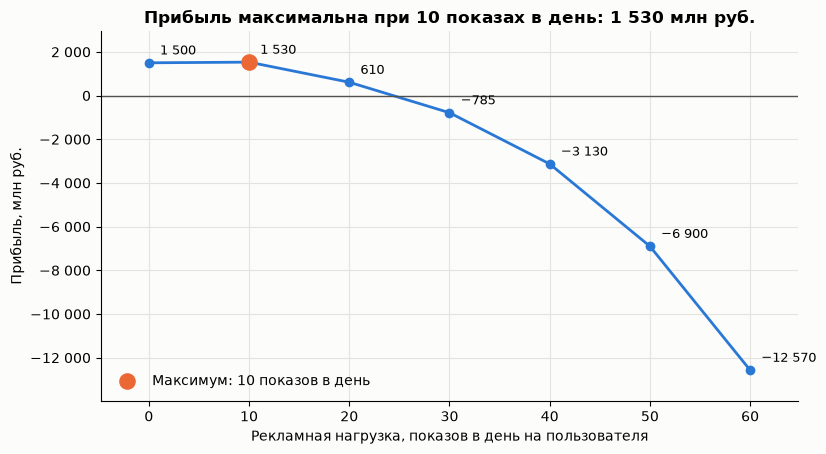

In [16]:
# График 1 (задание 6). Зависимость прибыли от рекламной нагрузки
profits = base_table["Прибыль"] / MLN
fig, ax = plt.subplots()
ax.plot(loads, profits, color=BLUE, linewidth=2, marker="o", markersize=6)
ax.axhline(0, color=GRAY, linewidth=1)
# Подписи значений у каждой точки
for load in loads:
    ax.annotate(fmt(profits[load]), (load, profits[load]), textcoords="offset points",
                xytext=(8, 6), fontsize=9)
# Оптимальная нагрузка выделена отдельной точкой
ax.scatter([optimal], [profits[optimal]], color=ORANGE, s=120, zorder=3,
           label=f"Максимум: {optimal} показов в день")
ax.set_xticks(loads)
ax.set_xlabel("Рекламная нагрузка, показов в день на пользователя")
ax.set_ylabel("Прибыль, млн руб.")
ax.set_title(f"Прибыль максимальна при {optimal} показах в день: "
             f"{fmt(profits[optimal])} млн руб.")
ax.yaxis.set_major_formatter(AXIS_FORMAT)
ax.legend(frameon=False, loc="lower left")
ax.margins(x=0.08, y=0.1)
fig.savefig(os.path.join(FIG_DIR, "04_profit.png"), dpi=160, bbox_inches="tight")
plt.show()

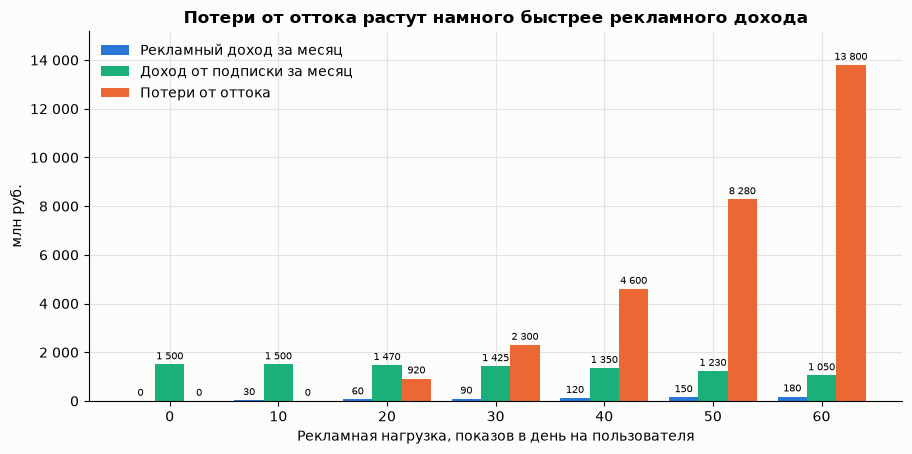

In [17]:
# График 2. Из чего складывается прибыль: доходы за месяц и потери от оттока
x = np.arange(len(loads))
width = 0.27
series = (
    ("Рекламный доход", BLUE, "Рекламный доход за месяц"),
    ("Доход подписки", GREEN, "Доход от подписки за месяц"),
    ("Потери оттока", ORANGE, "Потери от оттока"),
)
fig, ax = plt.subplots(figsize=(10.5, 4.8))
for index, (column, color, label) in enumerate(series):
    values = base_table[column] / MLN
    bars = ax.bar(x + (index - 1) * width, values, width, color=color, label=label)
    labels = []
    for value in values:
        labels.append(fmt(value))
    ax.bar_label(bars, labels=labels, padding=2, fontsize=7)
ax.set_xticks(x, loads)
ax.set_xlabel("Рекламная нагрузка, показов в день на пользователя")
ax.set_ylabel("млн руб.")
ax.set_title("Потери от оттока растут намного быстрее рекламного дохода")
ax.yaxis.set_major_formatter(AXIS_FORMAT)
ax.legend(frameon=False, loc="upper left")
ax.margins(y=0.1)
fig.savefig(os.path.join(FIG_DIR, "04_revenue_losses.png"), dpi=160, bbox_inches="tight")
plt.show()

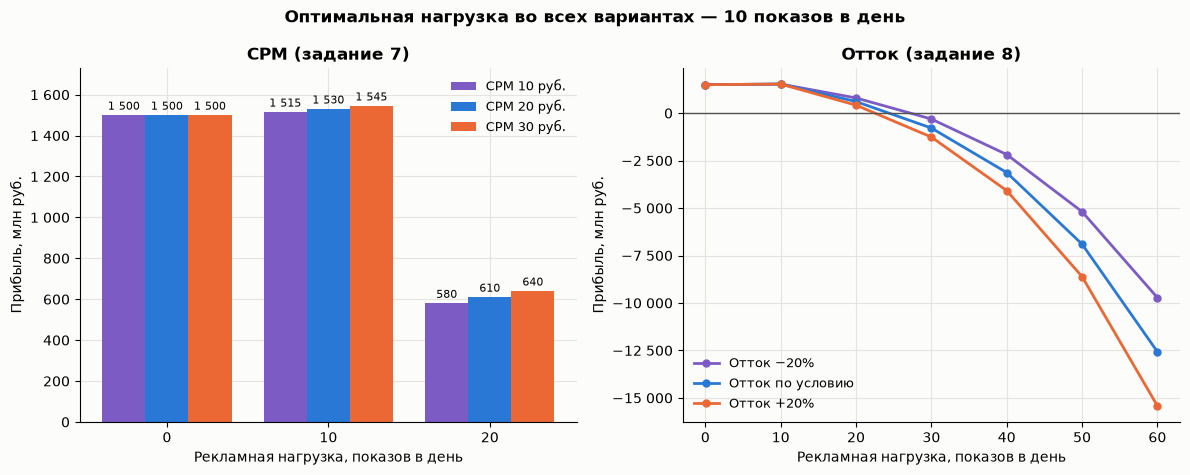

In [18]:
# График 3. Анализ чувствительности: слева — CPM, справа — отток
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.8))
variant_colors = (PURPLE, BLUE, ORANGE)

# Слева: первые три уровня нагрузки — на них видно, как CPM сдвигает прибыль
first_loads = loads[:3]
x = np.arange(len(first_loads))
count = len(BASE["cpm_variants"])                # число вариантов CPM
bar_width = 0.8 / count
for index, cpm in enumerate(BASE["cpm_variants"]):
    values = []
    for load in first_loads:
        values.append(cpm_tables[cpm].loc[load, "Прибыль"] / MLN)
    bars = left.bar(x + (index - (count - 1) / 2) * bar_width, values, bar_width,
                    color=variant_colors[index % len(variant_colors)],
                    label=f"CPM {fmt(cpm)} руб.")
    labels = []
    for value in values:
        labels.append(fmt(value))
    left.bar_label(bars, labels=labels, padding=2, fontsize=8)
left.set_xticks(x, first_loads)
left.set_xlabel("Рекламная нагрузка, показов в день")
left.set_ylabel("Прибыль, млн руб.")
left.set_title("CPM (задание 7)")
left.yaxis.set_major_formatter(AXIS_FORMAT)
left.legend(frameon=False, loc="upper right", fontsize=9)
left.margins(y=0.12)

# Справа: прибыль по всем уровням нагрузки при разном оттоке
for index, (label, table) in enumerate(churn_tables.items()):
    right.plot(loads, table["Прибыль"] / MLN, color=variant_colors[index], linewidth=2,
               marker="o", markersize=5, label=label)
right.axhline(0, color=GRAY, linewidth=1)
right.set_xticks(loads)
right.set_xlabel("Рекламная нагрузка, показов в день")
right.set_ylabel("Прибыль, млн руб.")
right.set_title("Отток (задание 8)")
right.yaxis.set_major_formatter(AXIS_FORMAT)
right.legend(frameon=False, loc="lower left", fontsize=9)

fig.suptitle(f"Оптимальная нагрузка во всех вариантах — {optimal} показов в день"
             if set(sens_summary["Оптимальная нагрузка, показов в день"]) == {optimal}
             else "Оптимальная нагрузка зависит от варианта", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "04_sensitivity.png"), dpi=160, bbox_inches="tight")
plt.show()

In [19]:
# Сохраняем главные показатели в файл reports/04_summary.json
summary = {
    "loads": loads,
    "ad_revenue": base_table["Рекламный доход"].tolist(),
    "subscription_revenue": base_table["Доход подписки"].tolist(),
    "lost_users": base_table["Ушло"].tolist(),
    "churn_losses": base_table["Потери оттока"].tolist(),
    "profit": base_table["Прибыль"].tolist(),
    "ltv": LTV,
    "loss_per_user": LOSS_PER_USER,
    "optimal_load": int(optimal),
    "optimal_profit": float(best["Прибыль"]),
    "optimal_load_by_marginal_rule": int(last_good),
    "profit_by_cpm": {},
    "optimal_load_by_cpm": {},
    "profit_by_churn": {},
    "optimal_load_by_churn": {},
    "result_per_user_by_segment": {},
    "optimal_load_by_segment": {},
}
for cpm, table in cpm_tables.items():
    summary["profit_by_cpm"][str(cpm)] = table["Прибыль"].tolist()
    summary["optimal_load_by_cpm"][str(cpm)] = int(cpm_optima[cpm])
for label, table in churn_tables.items():
    summary["profit_by_churn"][label] = table["Прибыль"].tolist()
    summary["optimal_load_by_churn"][label] = int(churn_optima[label])
for name in segments:
    summary["result_per_user_by_segment"][name] = segment_view[name].tolist()
    summary["optimal_load_by_segment"][name] = int(segment_optima[name])
with open(os.path.join("..", "reports", "04_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print("Показатели сохранены в reports/04_summary.json")

Показатели сохранены в reports/04_summary.json


## 3. Анализ результатов

### 3.1. Интерпретация полученных данных

- **Рекламный доход (задание 1).** Растет прямо пропорционально нагрузке: каждые 10 показов в день добавляют
  30 млн руб. в месяц. При максимальной нагрузке (60 показов, это 9 млрд показов в месяц) доход — 180 млн руб.
- **Доход от подписки (задание 2).** Без оттока подписка приносит 1 500 млн руб. в месяц — более чем в 8 раз
  больше, чем реклама при максимальной нагрузке. С ростом нагрузки доход падает: при 60 показах уходит 30% базы
  (1,5 млн человек), и подписка дает 1 050 млн руб.
- **Потери от оттока (задание 3).** Уход одного пользователя стоит 9 200 руб.: 2 000 руб. — затраты на его
  привлечение (CAC) и 7 200 руб. — доход, который он принес бы за 24 месяца (LTV). Уже при 20 показах уходит
  100 000 человек, потери — 920 млн руб. При 60 показах потери — 13 800 млн руб.
- **Прибыль (задание 4).** По уровням нагрузки: 1 500 → 1 530 → 610 → −785 → −3 130 → −6 900 → −12 570 млн руб.
  Прибыль растет только на первом шаге. Начиная с 30 показов в день платформа в убытке.
- **Оптимальная нагрузка (задание 5).** Максимум прибыли — 1 530 млн руб. — при 10 показах в день. Это последний
  уровень, на котором оттока еще нет: реклама добавляет 30 млн руб. и ничего не отнимает. При 10 видео в день
  это один показ рекламы на видео. Шаг до 20 показов не дает прироста дохода даже без учета потерь от оттока:
  реклама добавляет 30 млн руб., подписка теряет те же 30 млн руб., и общий доход остается равным 1 530 млн руб.
- **Проверка условием из лекции.** Шаг с 0 до 10 показов: рекламный доход растет на 30 млн руб., потери не растут —
  шаг выгоден. Шаг с 10 до 20: реклама дает те же 30 млн руб., а потери растут на 950 млн руб. (30 млн руб. —
  снижение подписки, 920 млн руб. — потери от оттока). Все следующие шаги тоже невыгодны. Вывод тот же: 10 показов.
- **Почему так.** Подписка приносит с пользователя 300 руб. в месяц, а реклама при 10 показах — 6 руб. Реклама —
  это 2% дохода платформы. Терять подписчика ради рекламы невыгодно: его уход стоит 9 200 руб.
- **Отток растет все быстрее.** Прирост оттока по шагам: 0, 2, 3, 5, 8 и 12 процентных пунктов. Это согласуется
  с функцией полезности из лекции (раздел 6.2): в ней есть слагаемое $\gamma \cdot Imp^2$ — эффект перегрузки
  рекламой, который растет быстрее самой нагрузки.

### 3.2. Сравнение с альтернативными вариантами

- **Чувствительность к CPM (задание 7).** При CPM 10, 20 и 30 руб. оптимальная нагрузка одна и та же —
  10 показов в день. Прибыль в оптимуме: 1 515, 1 530 и 1 545 млн руб., то есть CPM меняет ее на ±15 млн руб.
  (около 1%). Причина: шаг с 10 до 20 показов приносит 15, 30 или 45 млн руб. рекламы, а потери на этом шаге —
  950 млн руб. Изменение CPM на 10 руб. эту разницу не перекрывает.
- **Чувствительность к оттоку (задание 8).** При оттоке на 20% ниже и на 20% выше оптимальная нагрузка тоже
  10 показов. Прибыль в оптимуме не меняется (1 530 млн руб.), потому что при 10 показах оттока нет. Меняется
  прибыль на остальных уровнях: при 20 показах — 800, 610 и 420 млн руб.; при 30 показах — убыток в любом
  варианте (−310, −785 и −1 260 млн руб.).
- **Что важнее.** Ответ устойчив к обоим параметрам. Но прибыль при повышенной нагрузке зависит от оттока намного
  сильнее, чем от CPM: при 20 показах изменение оттока на 20% сдвигает прибыль на 190 млн руб., а изменение CPM
  на 50% — на 30 млн руб. Следить нужно в первую очередь за оттоком.
- **Сравнение с примером из лекции.** В примере лекции (раздел 6.3) оптимальная нагрузка — 30–40 показов в день,
  у нас — 10. Разница в том, что «ВидеоСервис» получает основной доход от подписки. Каждый ушедший пользователь
  забирает с собой подписку, поэтому потери от оттока очень быстро перекрывают рекламный доход.
- **Сегменты (задание 9).** Результат на одного пользователя за 24 месяца посчитан по тем же формулам для двух
  случаев. У пользователя с подпиской лучший результат — при 10 показах в день (7 344 руб.), то есть ответ тот же,
  что для всей платформы. Его уход стоит 9 200 руб., а реклама дает всего 6 руб. в месяц из 306 руб. У пользователя
  без подписки лучший результат — при 40 показах (376 руб.); при 30 показах — 332 руб., при 50 — 360 руб. Причина:
  реклама — его единственный доход, а уход стоит только 2 000 руб. (CAC), подписку он с собой не забирает.
  Это близко к примеру лекции, где оптимум — 30–40 показов. Но даже лучший результат (376 руб.) намного меньше
  CAC: на одной рекламе такой пользователь не окупается.
- **Время просмотра.** Оно снижается раньше, чем начинается отток: при 10 показах оттока нет, а время просмотра
  уже ниже на 4,2% (115 минут вместо 120). При 20 показах — ниже на 8,3%, при 60 — вдвое. Время просмотра можно
  использовать как ранний сигнал.
- **Ограничения расчета.** Доходы посчитаны за месяц, а потери от оттока — одной суммой за 24 месяца: так заданы
  формулы условия (допущение Д5). Доход ушедших подписчиков вычитается дважды: в задании 2 (они не платят
  в текущем месяце) и в задании 3 (ARPU × 24). Оптимум выбран из семи уровней таблицы: где именно между 10 и 20
  показами начинается отток, условие не говорит (допущение Д6). На ответ это не влияет: на сопоставимом сроке
  (24 месяца на одного пользователя с подпиской) лучший результат тоже при 10 показах.

## 4. Выводы и рекомендации

### 4.1. Ключевые выводы

1. **Оптимальная рекламная нагрузка — 10 показов в день на пользователя** (один показ на видео). Прибыль при ней
   максимальна: 1 530 млн руб.
2. Рекламный доход растет на 30 млн руб. за каждые 10 показов, а потери от оттока — намного быстрее: 920 млн руб.
   уже при 20 показах. Начиная с 30 показов платформа в убытке.
3. Основной доход платформы — подписка (1 500 млн руб. в месяц, 98% дохода). Реклама дает 30 млн руб. (2%).
   Поэтому главная задача — не потерять подписчиков: уход одного стоит 9 200 руб.
4. Ответ устойчив: оптимальная нагрузка остается равной 10 показам при CPM от 10 до 30 руб. и при изменении
   оттока на ±20%.
5. Прибыль зависит от оттока сильнее, чем от CPM. Отток и время просмотра — главные метрики для контроля.
6. Для сегментов ответ разный. Подписчикам — не выше 10 показов в день. Пользователям без подписки расчет
   допускает до 30–40 показов, но на одной рекламе они не окупают затраты на привлечение — их нужно переводить
   в подписку.

### 4.2. Практические рекомендации для «ВидеоСервис»

**Ответ на задание 5: оптимальная рекламная нагрузка — 10 показов в день на пользователя, прибыль 1 530 млн руб.**

**Рекомендации по сегментам (задание 9).** Ответ на задание 5 относится к платформе из условия, где подписку
платят все пользователи. Для сегментов расчет на одного пользователя (раздел 2.6) дает разные ответы.

| Сегмент | Рекомендуемая нагрузка | Обоснование |
|---|---|---|
| С подпиской | Не выше 10 показов в день (не больше одного показа на видео). Как вариант — подписка без рекламы | Лучший результат на пользователя — при 10 показах (7 344 руб. за 24 месяца). Реклама дает 6 руб. в месяц из 306 руб. (2%), а уход подписчика стоит 9 200 руб. Отказ от рекламы для подписчиков — это осознанный отказ от 30 млн руб. в месяц (2% прибыли) ради причины оставаться на подписке |
| Без подписки | Выше, чем у подписчиков: по расчету до 30–40 показов в день. Повышать ступенями (20 → 30 → 40) и проверять каждую на небольшой группе | Реклама — единственный доход с такого пользователя, а его уход стоит 2 000 руб. Лучший результат — при 40 показах (376 руб. за 24 месяца), при 30 — 332 руб. Расчет держится на допущении Д9: отток у этого сегмента взят из общей таблицы, поэтому без проверки сразу ставить 40 показов нельзя |

Общие правила для обоих сегментов:

- Цель для пользователей без подписки — перевод в подписку: подписчик приносит 300 руб. в месяц, а реклама даже
  при 40 показах — 24 руб. На одной рекламе пользователь без подписки не окупает CAC (376 руб. против 2 000 руб.).
  Подписка с меньшим числом рекламы — понятная причина ее оформить.
- Формат рекламы важен не меньше ее количества. По лекции (раздел 3.2) вынужденное внимание (например, всплывающая
  реклама) имеет очень низкую ценность для рекламодателя, а добровольное — высокую. Лучше показывать рекламу
  между видео, чем прерывать просмотр.
- Не строить дизайн на удержании любой ценой. Лекция (раздел 7.1) называет аддиктивный дизайн и манипуляцию
  поведением среди проблем экономики внимания.

**План мониторинга (задание 10).**

| Метрика | Значение при 10 показах | Сигнал для пересмотра нагрузки | Как часто |
|---|---|---|---|
| Рекламная нагрузка на пользователя | 10 показов в день | Выше 10 | Ежедневно |
| Отток пользователей | 0% | Выше, чем в контрольной группе; при 20 показах по условию — 2% | Еженедельно |
| Время просмотра | 115 мин в день | Ниже 115 мин; 110 мин — уровень 20 показов | Ежедневно |
| Доход от подписки | 1 500 млн руб. в месяц | Снижение | Ежемесячно |
| Рекламный доход | 30 млн руб. в месяц | Снижение при той же нагрузке | Ежемесячно |
| CPM | 20 руб. | Любое изменение — пересчитать прибыль (задание 7) | Ежемесячно |
| CTR, время удержания, вовлеченность, ROAS (метрики эффективности алгоритмов ранжирования) | В условии данных нет | Цели из лекции (раздел 4.3): выше 2%, выше 60 сек., выше 5%, выше 4x | Еженедельно |

Порядок действий:

1. Установить нагрузку 10 показов в день для подписчиков и зафиксировать исходные значения метрик.
2. Любое изменение нагрузки сначала проверять на небольшой группе пользователей и сравнивать ее с контрольной
   группой, где нагрузка не менялась, по оттоку и времени просмотра.
3. Время просмотра смотреть ежедневно как ранний сигнал: оно падает раньше, чем пользователи начинают уходить.
4. По данным теста пересчитать прибыль по формулам заданий 1–4. Если прибыль ниже прежней — вернуть прежнюю
   нагрузку.
5. При изменении CPM или оттока пересчитать таблицу прибыли: в ноутбуке для этого достаточно поменять значение
   в словаре `BASE` — таблицы и графики пересчитаются.